# Session 5 - Wav2Vec

Wav2Vec = raw audio -> cnn (ambil fitur2 penting) -> menghasilkan z -> masking (sembunyikan hasil z) -> transformer -> c (bandingkan q dan c) kalo bedanya jauh akan menghasilkan Loss (L) brati salah 

In [1]:
import torch
import torchaudio
import IPython
import matplotlib
import matplotlib.pyplot as plt

In [2]:
bundle = torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H
model = bundle.get_model()
print("Sample Rate:", bundle.sample_rate)
print("Labels:", bundle.get_labels())

Sample Rate: 16000
Labels: ('-', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z')


In [3]:
# Load file
import IPython.display 

SPEECH_FILE ="sample_audio.wav"
IPython.display.Audio(SPEECH_FILE)

In [4]:
# !pip install torchcodec

In [ ]:
# ini dari claude
import soundfile as sf
import torch
import torchaudio

data, sample_rate = sf.read(SPEECH_FILE, dtype="float32", always_2d=True)
waveform = torch.from_numpy(data.T)

In [ ]:
# Load speech file
# ini dari aslab harusnya bisa
# gabungin sample rate 1600 dari wav2vec nya + audio kita
# waveform, sample_rate = torchaudio.load(SPEECH_FILE)
if sample_rate != bundle.sample_rate:
    waveform = torchaudio.functional.resample(waveform, sample_rate, bundle.sample_rate)

In [14]:
with torch.inference_mode():
    emission, _ = model(waveform)
print(emission)

tensor([[[16.8257, -1.0946, -3.3573,  ..., -8.1836, -8.1038, -9.3254],
         [16.8472, -1.1345, -3.4505,  ..., -8.0638, -7.9588, -9.3393],
         [16.8901, -1.4776, -3.3926,  ..., -8.0826, -7.7958, -9.3544],
         ...,
         [16.7641, -0.1117, -3.2727,  ..., -8.4285, -8.6252, -9.2301],
         [16.8003, -0.0452, -3.2955,  ..., -8.5004, -8.7291, -9.2226],
         [16.7583,  0.2275, -3.2883,  ..., -8.5135, -8.7473, -9.2958]]])


In [15]:
print(emission.shape)
# 1 -> batch -> ada 1 audio yang diproses
# Time
# Class -> kemungkinan label yang ada

torch.Size([1, 773, 29])


In [16]:
emission[0].T.shape

torch.Size([29, 773])

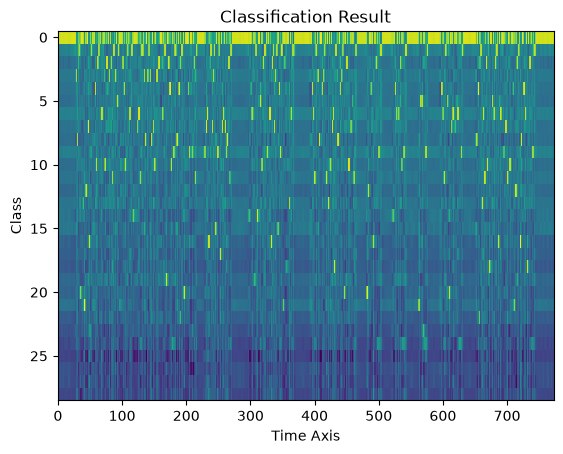

Labels:  ('-', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z')


In [18]:
plt.imshow(emission[0].T, interpolation="nearest", aspect="auto")
plt.title("Classification Result")
plt.xlabel("Time Axis")
plt.ylabel("Class")
plt.show()
print("Labels: ", bundle.get_labels())

In [19]:
# GREEDYTOCODER
class GreedyCTCDecoder(torch.nn.Module):
    # constructer
    def __init__(self, labels):
        super().__init__()
        self.labels = labels
        self.blank = 0

    # forward decoder
    def forward(self, emission: torch.Tensor) -> str:
        indices = torch.argmax(emission, dim=-1) # cari class dgn score terbesar
        indices = torch.unique_consecutive(indices, dim=-1) # untuk hapus karakter yg muncul berkali kali
        indices = [i for i in indices if i != self.blank] # hapus blank karakter
        return "".join([self.labels[i] for i in indices]) # ubah index ke huruf

In [20]:
decoder = GreedyCTCDecoder(labels=bundle.get_labels())
transcript = decoder(emission[0])

In [21]:
print(transcript)
IPython.display.Audio(SPEECH_FILE)

THE|PUBLIC|ARE|ENTREATED|TO|BEAR|IN|MIND|THAT|THIRTEEN|YEARS|HAVE|PASSED|SINCE|IT|WAS|FINISHED|MANY|MORE|SINCE|IT|WAS|BEGUN|AND|THAT|DURING|THAT|PERIOD|PLACES|MANNERS|BOOKS|AND|OPINIONS|HAVE|UNDERGONE|CONSIDERABLE|CHANGES|
